## Historic SUMMA ensemble

Each member keeps its own forcing. SUMMA runs once from start to end, then mizuRoute routes that member. No assimilation and no ESP.

In [6]:
from pathlib import Path

%load_ext autoreload
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
from snowda.workflows.run_summa_historic import run_summa_historic

config_path = Path("../runs/examples/ross_summa_historic.yaml").resolve()
run_dir = run_summa_historic(config_path)
print("Historic run dir:", run_dir)

In [21]:
from pathlib import Path
from snowda.workflows.run_summa import run_summa
config_path = Path("../runs/examples/chena_summa_historic_ensemble_mean.yaml").resolve()
run_dir = run_summa(config_path)

2026-10-26 15:16:32 | INFO     | snowda.snowda.config.pysummada | output_dir not set; defaulting to /Users/dcasson/GitHub/snowda/outputs/chena_summa_deterministic
2026-10-26 15:16:32 | INFO     | snowda.snowda.workflows.run_summa | snowda SUMMA deterministic run starting
2026-10-26 15:16:32 | INFO     | snowda.snowda.workflows.run_summa | Config: /Users/dcasson/GitHub/snowda/runs/examples/chena_summa_historic_ensemble_mean.yaml
2026-10-26 15:16:32 | INFO     | snowda.snowda.workflows.run_summa | Run dir: /Users/dcasson/GitHub/snowda/outputs/chena_summa_deterministic/20261026T211632Z
2026-10-26 15:16:32 | INFO     | snowda.snowda.workflows.run_summa | Wrote config snapshot: /Users/dcasson/GitHub/snowda/outputs/chena_summa_deterministic/20261026T211632Z/config.resolved.json
2026-10-26 15:16:32 | INFO     | snowda.snowda.io.summa_ensemble | Creating output directories
2026-10-26 15:16:32 | INFO     | snowda.snowda.io.summa_ensemble | Deleting ensemble files in /Users/dcasson/Data/snowda/s

## Historic ensemble

Gray lines are every historic ensemble member. There are no assimilation times and no ESP forecasts. Streamflow is mizuRoute discharge for the full window. The orange line is the gauge.

Plotting /Users/dcasson/GitHub/snowda/outputs/chena_summa_deterministic/20261026T211632Z


2026-10-26 15:32:49 | INFO     | snowda.snowda.io.da_traces | Loaded DA traces from /Users/dcasson/GitHub/snowda/outputs/chena_summa_deterministic/20261026T211632Z: 1 historic members, 0 states, 0 forecasts
2026-10-26 15:32:51 | INFO     | snowda.snowda.io.da_traces | Loaded DA traces from /Users/dcasson/GitHub/snowda/outputs/chena_summa_deterministic/20261026T211632Z: 1 historic members, 0 states, 0 forecasts


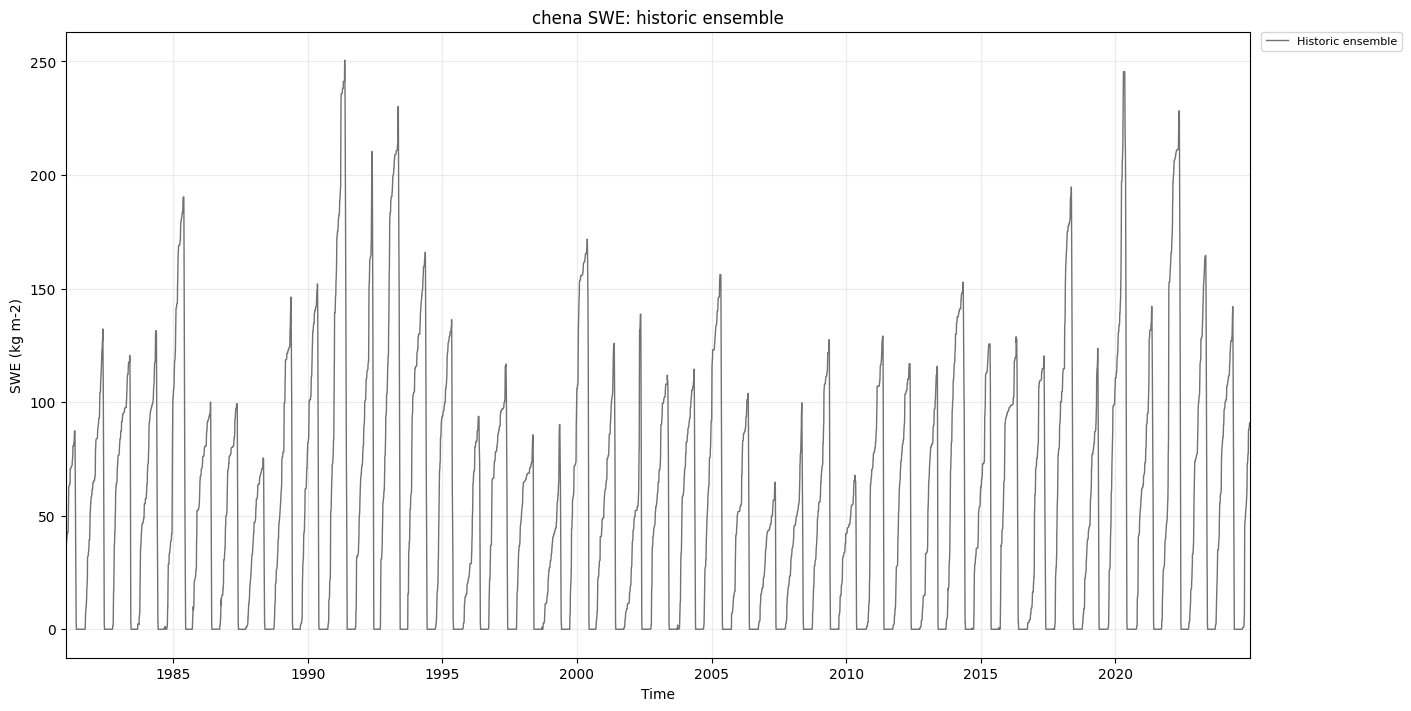

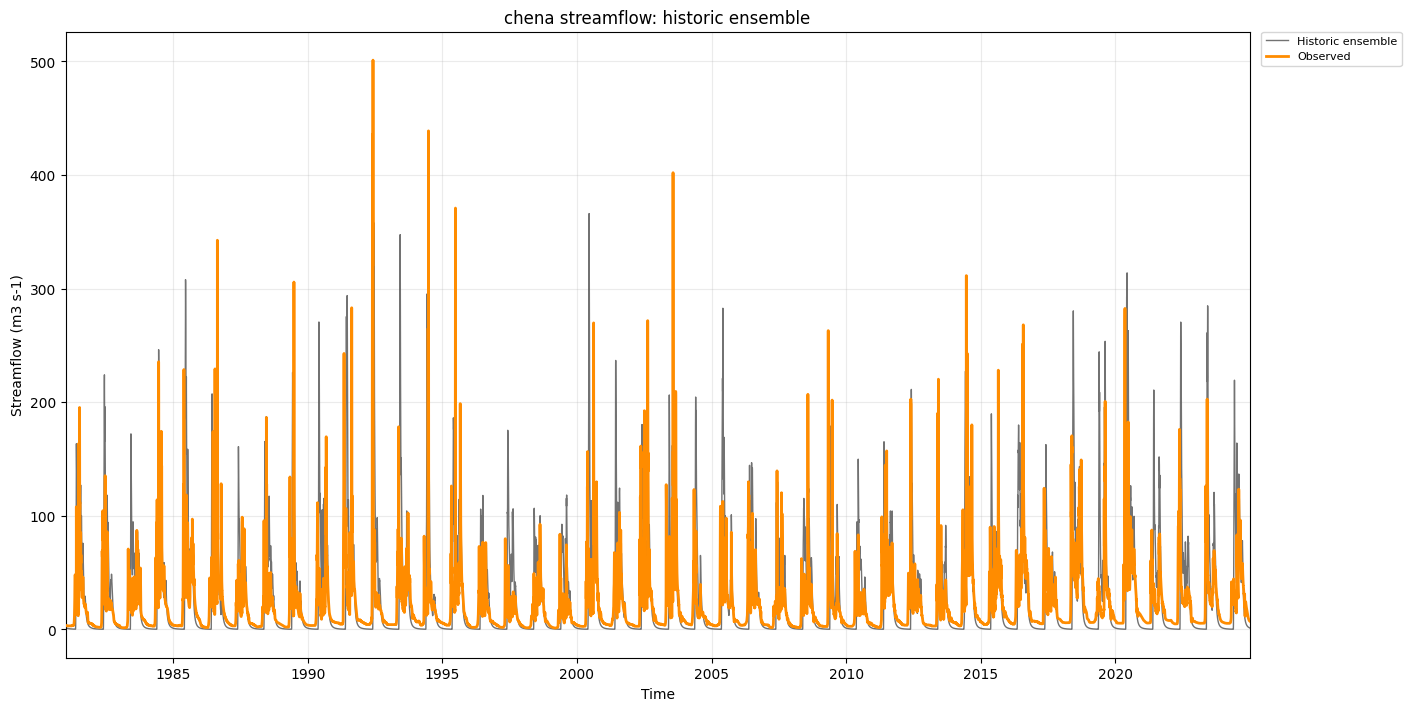

In [24]:
from pathlib import Path

import yaml

from snowda.io.da_traces import load_da_streamflow, load_da_swe
from snowda.io.streamflow import read_streamflow_observations
from snowda.viz.summa_da import plot_da_traces

catchment = "chena"
if "run_dir" in globals() and (Path(run_dir) / "summa").is_dir():
    historic_run_dir = Path(run_dir)
else:
    run_root = Path(f"../outputs/{catchment}_summa_historic")
    historic_run_dir = max(
        (path for path in run_root.iterdir() if (path / "summa").is_dir()),
        key=lambda path: path.stat().st_mtime,
    )
print("Plotting", historic_run_dir)

figure_dir = historic_run_dir / "figures"
figure_dir.mkdir(exist_ok=True)

swe = load_da_swe(historic_run_dir)
fig, _ax = plot_da_traces(
    swe,
    title=f"{catchment} SWE: historic ensemble",
)
fig.savefig(figure_dir / "historic_swe.png", dpi=150, bbox_inches="tight")

eval_cfg = yaml.safe_load(
    Path(f"../runs/examples/{catchment}_evaluate_streamflow.yaml").read_text()
)
obs = read_streamflow_observations(eval_cfg["obs_csv"])
topology_nc = historic_run_dir / "mizuroute" / "topology.nc"
if not topology_nc.is_file():
    det_root = Path(f"../outputs/{catchment}_summa_deterministic")
    candidates = sorted(
        det_root.glob("*/mizuroute/topology.nc"),
        key=lambda path: path.stat().st_mtime,
    )
    topology_nc = candidates[-1] if candidates else None
flow = load_da_streamflow(historic_run_dir, topology_nc=topology_nc)
fig, _ax = plot_da_traces(
    flow,
    obs,
    title=f"{catchment} streamflow: historic ensemble",
)
fig.savefig(figure_dir / "historic_streamflow.png", dpi=150, bbox_inches="tight")

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

from snowda.obs_qm.seasonal import water_year


def _trace_times(traces) -> pd.DatetimeIndex:
    pieces = [
        pd.DatetimeIndex(pd.to_datetime(segment["time"].values))
        for member in traces.historic
        for segment in member.segments
    ]
    if not pieces:
        return pd.DatetimeIndex([])
    times = pieces[0]
    for piece in pieces[1:]:
        times = times.union(piece)
    return times


# Water year starts 1 October: 1 Oct 2015 belongs to water year 2016.
times = _trace_times(swe).union(_trace_times(flow))
water_years = sorted({int(year) for year in water_year(times)})
wy_dir = figure_dir / "water_years"
wy_dir.mkdir(exist_ok=True)

for wy in water_years:
    start = pd.Timestamp(year=wy - 1, month=10, day=1)
    end = pd.Timestamp(year=wy, month=10, day=1) - pd.Timedelta(seconds=1)
    fig, _ax = plot_da_traces(
        swe,
        start=start,
        end=end,
        title=f"Ross SWE: water year {wy}",
    )
    fig.savefig(wy_dir / f"historic_swe_wy{wy}.png", dpi=150, bbox_inches="tight")
    plt.close(fig)

    fig, _ax = plot_da_traces(
        flow,
        obs,
        start=start,
        end=end,
        title=f"Ross streamflow: water year {wy}",
    )
    fig.savefig(wy_dir / f"historic_streamflow_wy{wy}.png", dpi=150, bbox_inches="tight")
    plt.close(fig)

print(f"Wrote {len(water_years)} water years to {wy_dir}")


Wrote 45 water years to /Users/dcasson/GitHub/snowda/outputs/chena_summa_deterministic/20261026T211632Z/figures/water_years
